<a href="https://colab.research.google.com/github/tbeltranx/curso_ANN/blob/main/01_AnExp_Depuracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Introducción: Análisis exploratorio y depuración de datos para el desarrollo de modelos predictivos

## Objetivo del ejercicio

El presente ejercicio tiene como objetivo **evaluar la calidad, disponibilidad y completitud de un conjunto de datos**, mediante herramientas de análisis y visualización implementadas en Python, como etapa preparatoria para su utilización en modelos estadísticos y de aprendizaje automático.

El procedimiento se desarrolla en el entorno de Google Colab, utilizando principalmente las bibliotecas Pandas, Matplotlib y Seaborn para la manipulación, inspección y representación gráfica de los datos.

## Descripción del conjunto de datos

El análisis parte de un archivo denominado `AD_data.csv`, almacenado en Google Drive, que contiene **2,062 registros y 71 variables**.

Inicialmente, se examina la estructura del conjunto de datos para identificar los tipos de variables, la cantidad de observaciones disponibles y la presencia de valores faltantes.

Posteriormente, se analiza la completitud de las variables numéricas, prestando especial atención a las 20 columnas con mayor número de valores no nulos.

La variable `lignin` se utiliza como criterio principal para seleccionar un subconjunto de registros con información disponible, que servirá como base para las siguientes etapas de depuración.

## Metodología

El procedimiento comprende cinco etapas principales:

1. **Importación e inspección de datos.** Se establece la conexión con Google Drive, se importa el archivo CSV y se examina la estructura del DataFrame original.

2. **Evaluación general de valores faltantes.** Se genera un mapa de calor para identificar visualmente la distribución de los valores nulos en las 71 variables del conjunto de datos.

3. **Análisis de disponibilidad de variables numéricas.** Se identifican las 20 columnas numéricas con mayor cantidad de valores no nulos. Los resultados se representan mediante una gráfica de barras y un mapa de calor, permitiendo evaluar tanto la cantidad como la distribución de la información disponible.

4. **Filtrado de registros mediante la variable `lignin`.** Se seleccionan únicamente las observaciones que contienen un valor válido de esta variable, reduciendo el conjunto de datos de 2,062 a 417 registros, equivalentes al **20.22 % del total original**.

5. **Eliminación de columnas completamente vacías.** Se eliminan las variables que no contienen información en ninguno de los 417 registros seleccionados, conservando aquellas que presentan al menos un valor válido.

## Resultados esperados

Al finalizar estas etapas se obtiene un conjunto de datos depurado que conserva los registros con información válida de `lignin` y excluye las columnas completamente vacías.

El procedimiento permite identificar las variables con mayor disponibilidad de información, reconocer patrones de valores faltantes y establecer una base de datos más adecuada para posteriores análisis.

Sin embargo, algunas de las variables conservadas pueden continuar presentando valores nulos, por lo que podrían requerirse criterios adicionales de selección, tratamiento de datos faltantes o evaluación de su relevancia estadística.

## Alcance del ejercicio

Este ejercicio corresponde a una **fase inicial de análisis exploratorio y preparación de datos**. No incluye todavía la imputación de valores faltantes, la normalización de variables, la identificación de valores atípicos ni la construcción de modelos predictivos.

Su finalidad es establecer un procedimiento sistemático y reproducible para evaluar la disponibilidad de información y seleccionar un subconjunto de datos que pueda utilizarse en etapas posteriores de análisis y modelado.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
from google.colab import drive
drive.mount('/content/drive')

file_path='/content/drive/MyDrive/Colab Notebooks/AI book/AD_data.csv'
df = pd.read_csv(file_path)

print(df.info())


Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2062 entries, 0 to 2061
Data columns (total 71 columns):
 #   Column                                                          Non-Null Count  Dtype  
---  ------                                                          --------------  -----  
 0   substrate identification                                        2062 non-null   object 
 1   substrate name                                                  2062 non-null   object 
 2   substrate class in database                                     2062 non-null   object 
 3   pH                                                              226 non-null    float64
 4   carbon                                                          151 non-null    float64
 5   nitrogen                                                        238 non-null    float64
 6   sugar                                                           115 non-null    float64
 7   fat                      


## Interpretación

Este código realiza la **importación de bibliotecas de Python, la conexión con Google Drive y la carga de un conjunto de datos** almacenado en un archivo CSV (*Comma-Separated Values*).

Posteriormente, muestra información general sobre la estructura del conjunto de datos, incluyendo el número de registros, las columnas disponibles, los tipos de datos y la cantidad de valores no nulos.

El procedimiento constituye la **etapa inicial de preparación y exploración de datos**, necesaria antes de realizar operaciones de limpieza, análisis estadístico, visualización o construcción de modelos predictivos.

### Procedimiento

1. **Importa la biblioteca Pandas** mediante `import pandas as pd`. Esta biblioteca permite manipular y analizar datos estructurados utilizando objetos como los DataFrames.

2. **Importa la biblioteca Seaborn** mediante `import seaborn as sns`. Seaborn proporciona herramientas para generar visualizaciones estadísticas, como mapas de calor, diagramas de dispersión y gráficas de distribución.

3. **Importa Matplotlib** mediante `import matplotlib.pyplot as plt`. Esta biblioteca permite crear y personalizar gráficas. Aunque Seaborn y Matplotlib se importan en esta etapa, todavía no se utilizan para generar visualizaciones.

4. **Importa el módulo de Google Drive** mediante `from google.colab import drive`. Este módulo permite acceder a los archivos almacenados en Google Drive desde el entorno de ejecución de Google Colab.

5. **Monta Google Drive** mediante `drive.mount('/content/drive')`. Esta instrucción establece la conexión entre Google Colab y Google Drive, permitiendo acceder a los archivos almacenados en la cuenta autorizada. Durante la ejecución puede solicitarse la autenticación del usuario.

6. **Define la ruta del archivo CSV** mediante la variable `file_path`. La ruta especificada es:

   `/content/drive/MyDrive/Colab Notebooks/AI book/AD_data.csv`

   Esta ubicación corresponde a un archivo denominado `AD_data.csv`, almacenado en la carpeta `AI book`, dentro de `Colab Notebooks` de Google Drive.

7. **Carga el archivo CSV en un DataFrame** mediante `pd.read_csv(file_path)`. Pandas interpreta el contenido del archivo y construye una estructura tabular denominada `df`, donde las filas representan registros y las columnas representan variables.

8. **Muestra información general del DataFrame** mediante `df.info()`. Esta función proporciona:
   - **Número de registros:** cantidad total de filas del conjunto de datos.
   - **Número de columnas:** cantidad de variables disponibles.
   - **Nombres de las columnas:** identificadores de las variables.
   - **Valores no nulos:** número de registros con información disponible en cada columna.
   - **Tipos de datos:** clasificación de las variables, como `int64`, `float64` u `object`.
   - **Uso de memoria:** estimación de los recursos de memoria utilizados por el DataFrame.

### Observaciones importantes

- El código está diseñado para ejecutarse en **Google Colab**, ya que utiliza el módulo `google.colab` para acceder a Google Drive.
- La ruta del archivo debe corresponder exactamente con su ubicación en Google Drive; de lo contrario, se producirá un error de archivo no encontrado.
- La función `pd.read_csv()` utiliza por defecto la coma como separador de campos. Si el archivo emplea otro delimitador, será necesario especificarlo mediante el parámetro `sep`.
- Pandas identifica automáticamente los tipos de datos, aunque esta clasificación puede requerir ajustes posteriores.
- La función `df.info()` permite detectar preliminarmente columnas con valores faltantes, comparando el número de valores no nulos con el total de registros.
- La instrucción `print(df.info())` genera la información solicitada, pero también muestra un valor `None` al final, debido a que `info()` imprime directamente sus resultados y no devuelve un objeto con la información.

  Por ello, es preferible utilizar:

  ```python
  df.info()
  ```

- La ejecución del código no modifica el archivo CSV original. Los datos se cargan en memoria para su posterior procesamiento.

### Conclusión

Esta etapa permite **establecer el entorno de trabajo y verificar la estructura inicial del conjunto de datos**, proporcionando información fundamental para planificar las siguientes operaciones de análisis.

La inspección mediante `df.info()` facilita la identificación preliminar de variables numéricas y categóricas, así como la detección de posibles problemas de completitud.

Sin embargo, esta inspección no permite evaluar por sí sola la calidad de los datos, la existencia de registros duplicados, valores atípicos o inconsistencias en las mediciones.

**El procedimiento es exclusivamente de carga e inspección inicial:** no elimina registros, no modifica variables, no realiza imputaciones y no transforma el conjunto de datos original.


<function matplotlib.pyplot.show(close=None, block=None)>

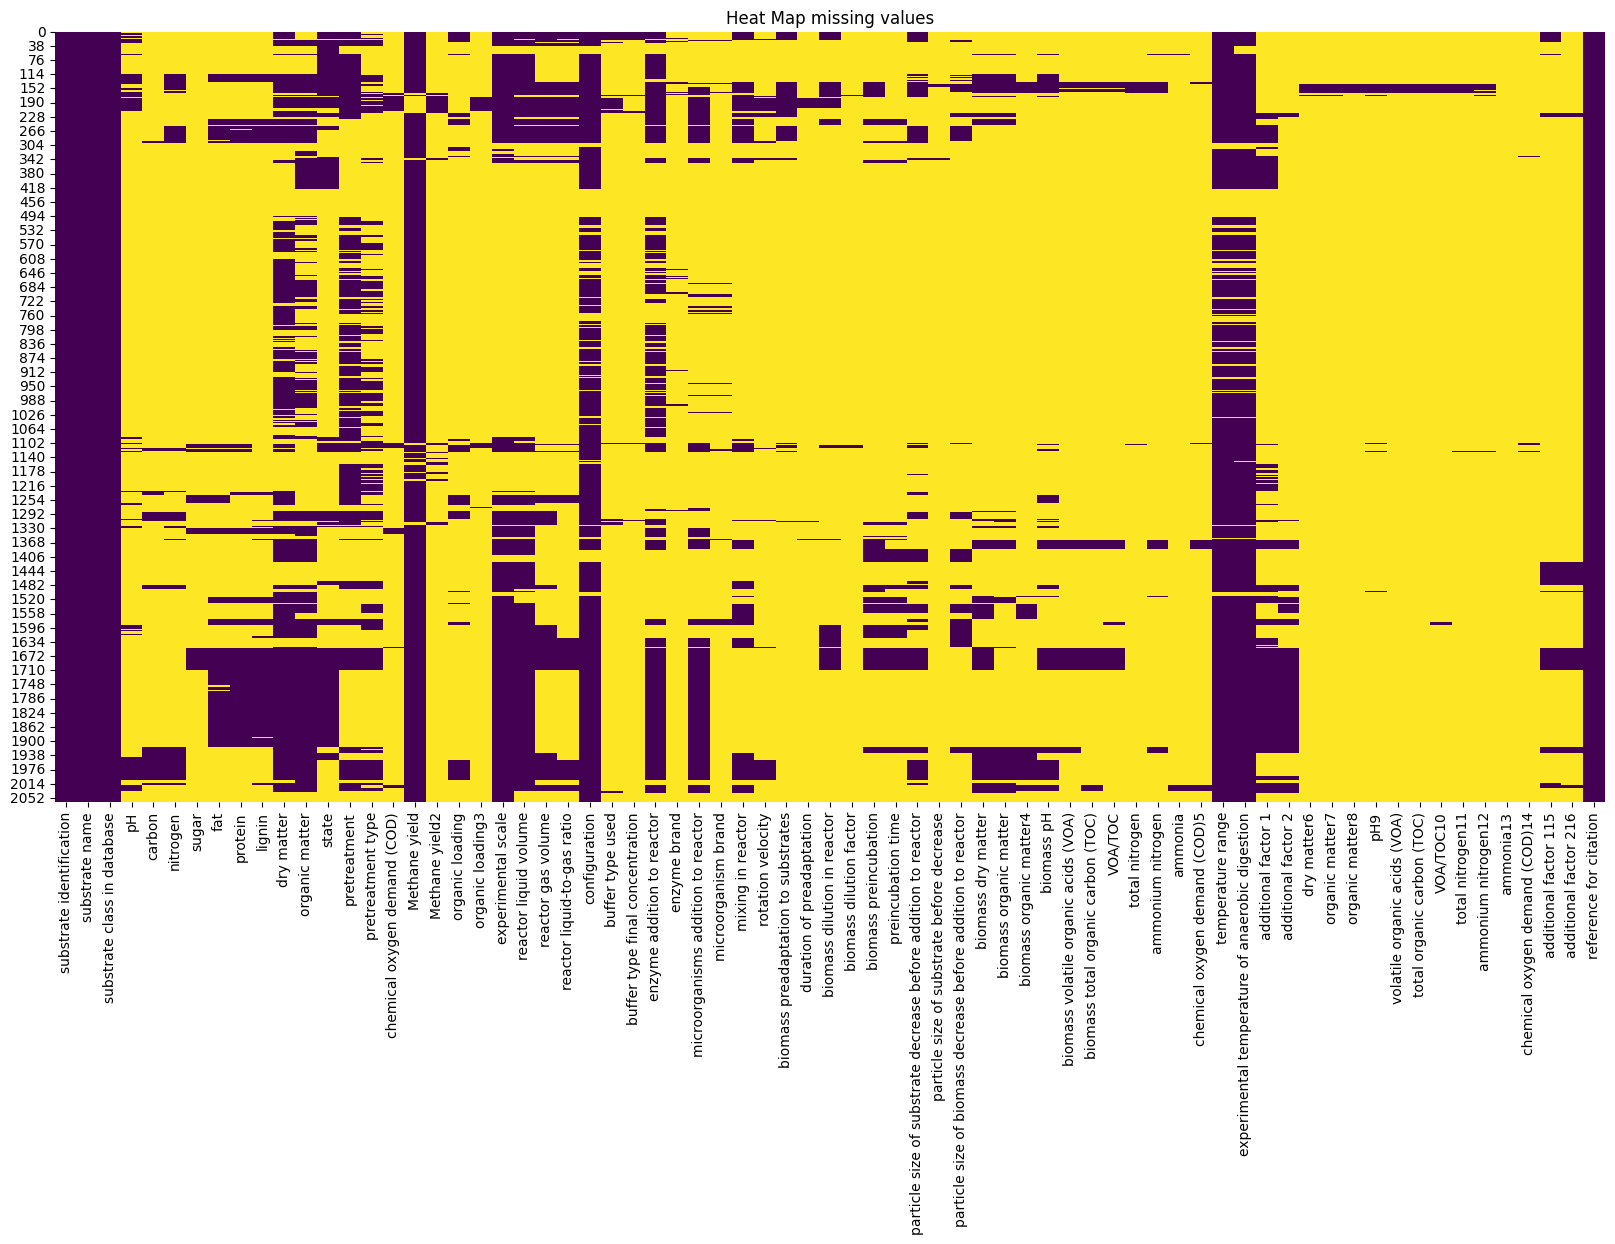

In [4]:
plt.figure(figsize=(20, 10))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heat Map missing values')
plt.show


## Interpretación

Este código genera un **mapa de calor (*heatmap*) para visualizar la distribución de los valores faltantes** en el DataFrame original (`df`), utilizando las bibliotecas Matplotlib y Seaborn.

La representación gráfica permite identificar visualmente qué variables presentan datos faltantes (`NaN`), cómo se distribuyen entre los registros y si existen patrones de ausencia de información.

El procedimiento constituye una **etapa de análisis exploratorio de la calidad y completitud de los datos**, útil para determinar las estrategias de limpieza y preparación que deberán aplicarse posteriormente.

### Procedimiento

1. **Define las dimensiones de la figura** mediante `plt.figure(figsize=(20, 10))`. Se establece un área gráfica de 20 pulgadas de ancho por 10 pulgadas de alto, proporcionando espacio suficiente para representar las filas y columnas del DataFrame.

2. **Identifica los valores faltantes** mediante `df.isnull()`. Esta función genera una matriz de valores booleanos con las mismas dimensiones del DataFrame original:
   - **`True`:** indica que el elemento contiene un valor nulo (`NaN`).
   - **`False`:** indica que el elemento contiene un valor no nulo.

3. **Genera el mapa de calor** mediante `sns.heatmap(df.isnull(), cbar=False, cmap='viridis')`. Cada celda de la matriz se representa mediante un color, permitiendo distinguir visualmente los datos disponibles de los faltantes.

4. **Aplica la paleta de colores `viridis`**, que utiliza diferentes tonalidades para representar los valores booleanos:
   - **Morado oscuro:** corresponde a valores no nulos (`False`, equivalente a 0).
   - **Amarillo:** corresponde a valores nulos (`True`, equivalente a 1).

5. **Desactiva la barra de colores** mediante `cbar=False`. Esta opción elimina la escala lateral de colores, simplificando la presentación de la gráfica.

6. **Asigna un título a la gráfica** mediante `plt.title('Heat Map missing values')`, identificando el contenido como un mapa de calor de valores faltantes.

7. **Muestra la representación gráfica** mediante `plt.show()`, permitiendo observar la distribución de los valores nulos en el conjunto de datos.

### Interpretación de la gráfica

El mapa de calor representa la estructura de disponibilidad de información del DataFrame:

- **Eje horizontal (X):** corresponde a las columnas o variables del conjunto de datos.
- **Eje vertical (Y):** corresponde a los registros o filas del DataFrame.
- **Regiones moradas:** indican posiciones donde existen datos disponibles.
- **Regiones amarillas:** indican posiciones donde existen valores faltantes.

La distribución de colores permite identificar diferentes situaciones:

1. **Columnas predominantemente moradas:** variables con alta disponibilidad de información.
2. **Columnas predominantemente amarillas:** variables con una proporción elevada de valores faltantes.
3. **Columnas completamente amarillas:** variables que no contienen ningún valor válido.
4. **Franjas horizontales amarillas:** registros que presentan valores faltantes en varias variables.
5. **Bloques o patrones de colores:** posibles agrupaciones de registros con características similares de disponibilidad de información.

### Observaciones importantes

- El análisis se realiza sobre todas las columnas del DataFrame original (`df`), independientemente de si contienen variables numéricas, categóricas o de otro tipo.
- La función `isnull()` identifica los valores faltantes reconocidos por Pandas, como `NaN`, `None` y `NaT`.
- Las celdas que contienen cadenas vacías (`''`) o valores utilizados convencionalmente para representar datos faltantes, como `0`, `-999` o `N/A` almacenado como texto, pueden requerir una limpieza previa para identificarse correctamente.
- El mapa de calor permite reconocer patrones visuales de ausencia de información, pero no proporciona directamente el número o porcentaje de valores faltantes por variable.
- Cuando el DataFrame contiene una gran cantidad de registros, la representación puede resultar muy densa y dificultar la identificación de valores individuales.
- La presencia de patrones similares de datos faltantes entre diferentes columnas puede sugerir relaciones en los mecanismos de recopilación de información, aunque no permite establecer por sí sola las causas de dichas ausencias.

### Conclusión

Esta etapa permite realizar una **evaluación visual preliminar de la completitud del conjunto de datos**, identificando variables y registros que presentan información faltante.

El mapa de calor facilita la detección de patrones de ausencia de datos y proporciona elementos para decidir si conviene eliminar determinadas columnas, filtrar registros o aplicar técnicas de imputación.

Sin embargo, la selección de una estrategia de tratamiento de valores faltantes debe considerar también la importancia de cada variable, el porcentaje de información disponible y las posibles causas de la ausencia de datos.

**El procedimiento es exclusivamente exploratorio y visual:** no elimina filas ni columnas, no modifica valores y no realiza imputaciones sobre el DataFrame original.


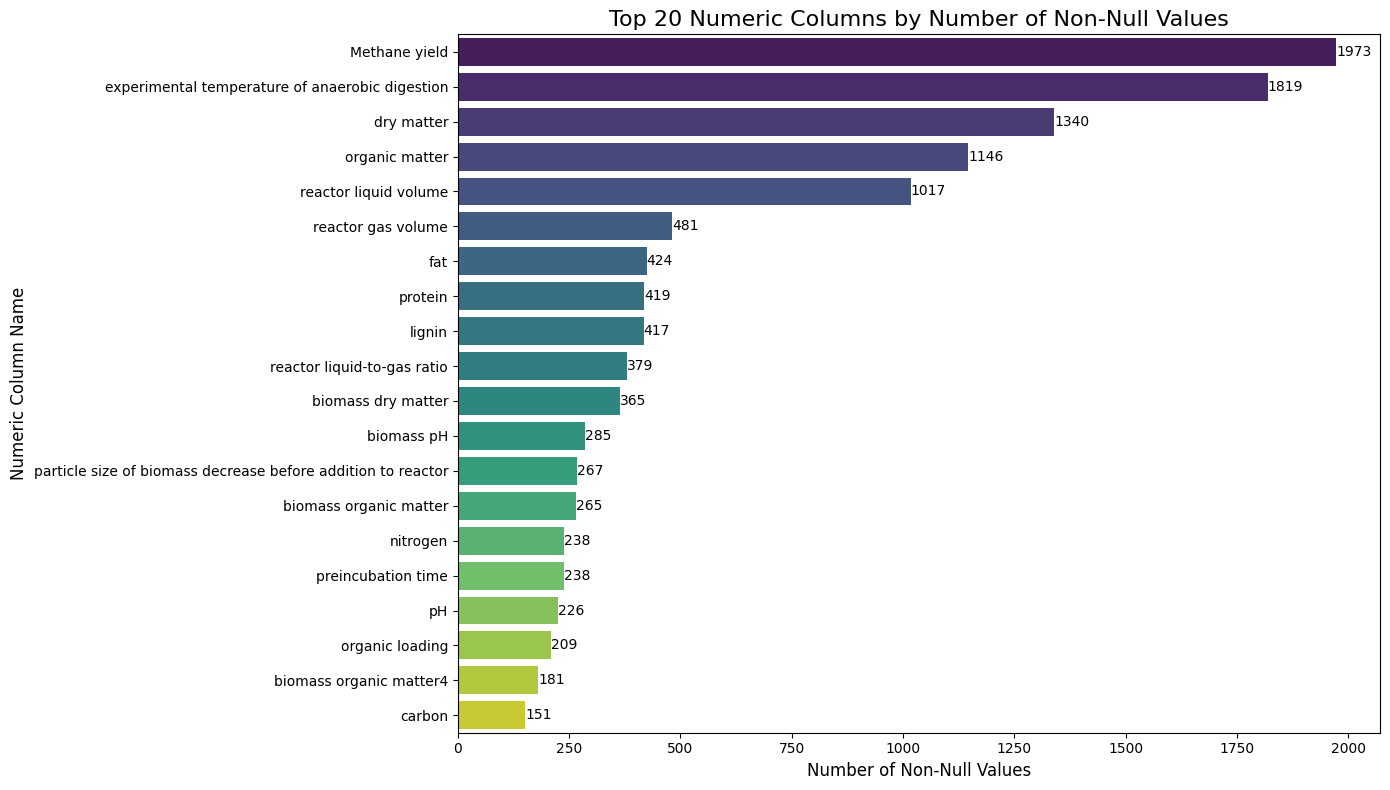

In [6]:
# Select only numeric columns
numric_df=df.select_dtypes(include=['number'])
# Calculate the number of non-null
non_null_counts_numeric = numric_df.count()
# Calculate the number of null
null_counts_numeric = numric_df.isnull().sum()
# sort in descending order and select tje top 20 numeric column
top_20_non_null_numeric = non_null_counts_numeric.sort_values(ascending=False).head(20)

#create a bar plot for top 20 numeric columns
plt.figure(figsize=(14, 8))
ax= sns.barplot(x=top_20_non_null_numeric.values, y=top_20_non_null_numeric.index, hue=top_20_non_null_numeric.index, palette='viridis', legend=False)
plt.title('Top 20 Numeric Columns by Number of Non-Null Values', fontsize=16)
plt.xlabel('Number of Non-Null Values', fontsize=12)
plt.ylabel('Numeric Column Name', fontsize=12)

for index, value in enumerate(top_20_non_null_numeric.values):
    ax.text(value, index, str(value), color='black', ha='left', va='center')

plt.tight_layout()
plt.show()



## Interpretación

Este código realiza un análisis de la disponibilidad de datos en las columnas numéricas del DataFrame original (`df`), identificando las **20 variables numéricas con mayor cantidad de valores no nulos** y representando los resultados mediante una gráfica de barras horizontales.

El procedimiento permite reconocer qué variables tienen mayor cantidad de información disponible y, por tanto, cuáles podrían ser más adecuadas para posteriores análisis estadísticos o modelos predictivos.

### Procedimiento

1. **Selecciona únicamente las columnas numéricas** del DataFrame original mediante `select_dtypes(include=['number'])`. Se excluyen las columnas que contienen texto, fechas u otros tipos de datos no numéricos.

2. **Calcula el número de valores no nulos** de cada columna numérica utilizando `count()`. Este resultado se almacena en `non_null_counts_numeric` y representa la cantidad de registros con información disponible para cada variable.

3. **Calcula el número de valores nulos** (`NaN`) de cada columna mediante `isnull().sum()`. Los resultados se almacenan en `null_counts_numeric`, aunque esta variable no se utiliza posteriormente en el código.

4. **Ordena las columnas numéricas** de mayor a menor cantidad de valores no nulos utilizando `sort_values(ascending=False)`.

5. **Selecciona las primeras 20 columnas** mediante `head(20)`. Estas corresponden a las variables numéricas con mayor cantidad de registros disponibles y se almacenan en `top_20_non_null_numeric`.

6. **Genera una gráfica de barras horizontales** utilizando `sns.barplot()` de Seaborn. La gráfica presenta:
   - **Eje horizontal (X):** número de valores no nulos.
   - **Eje vertical (Y):** nombres de las columnas numéricas.
   - **Colores:** paleta `viridis`, que permite distinguir visualmente las variables.
   - **Dimensiones:** 14 × 8 pulgadas.

7. **Agrega etiquetas numéricas a las barras** mediante un ciclo `for` y la función `ax.text()`. Cada barra muestra el número exacto de registros no nulos correspondiente a la variable.

8. **Ajusta y presenta la gráfica** utilizando `plt.tight_layout()` para mejorar la distribución de los elementos y `plt.show()` para visualizar el resultado.

### Observaciones importantes

- El análisis se realiza sobre el DataFrame original (`df`), sin aplicar filtros previos sobre los registros.
- La selección considera exclusivamente columnas numéricas, independientemente de su significado físico o estadístico.
- El criterio de clasificación es la **cantidad absoluta de valores no nulos**, no el porcentaje de datos disponibles.
- Las variables con mayor número de registros no necesariamente son las más relevantes para un modelo predictivo.
- El cálculo de valores nulos (`null_counts_numeric`) se realiza correctamente, pero sus resultados no se muestran ni se utilizan en la gráfica.
- La variable `numric_df` contiene un error ortográfico en su nombre (debería ser `numeric_df`), aunque esto no afecta la ejecución del código porque se utiliza de manera consistente.
- Si existen menos de 20 columnas numéricas, la gráfica mostrará únicamente las disponibles.

### Conclusión

Esta etapa permite evaluar preliminarmente la **completitud de las variables numéricas** del conjunto de datos, identificando aquellas que presentan mayor disponibilidad de información.

La gráfica facilita la comparación entre variables y puede utilizarse como criterio inicial para seleccionar las columnas que participarán en análisis estadísticos, estudios de correlación o modelos de aprendizaje automático.

Sin embargo, la disponibilidad de datos debe complementarse con otros criterios, como la relevancia de las variables, su variabilidad, la calidad de las mediciones y su relación con la variable objetivo.

**El procedimiento es exclusivamente exploratorio:** no elimina columnas, no modifica registros y no realiza imputación de valores faltantes.


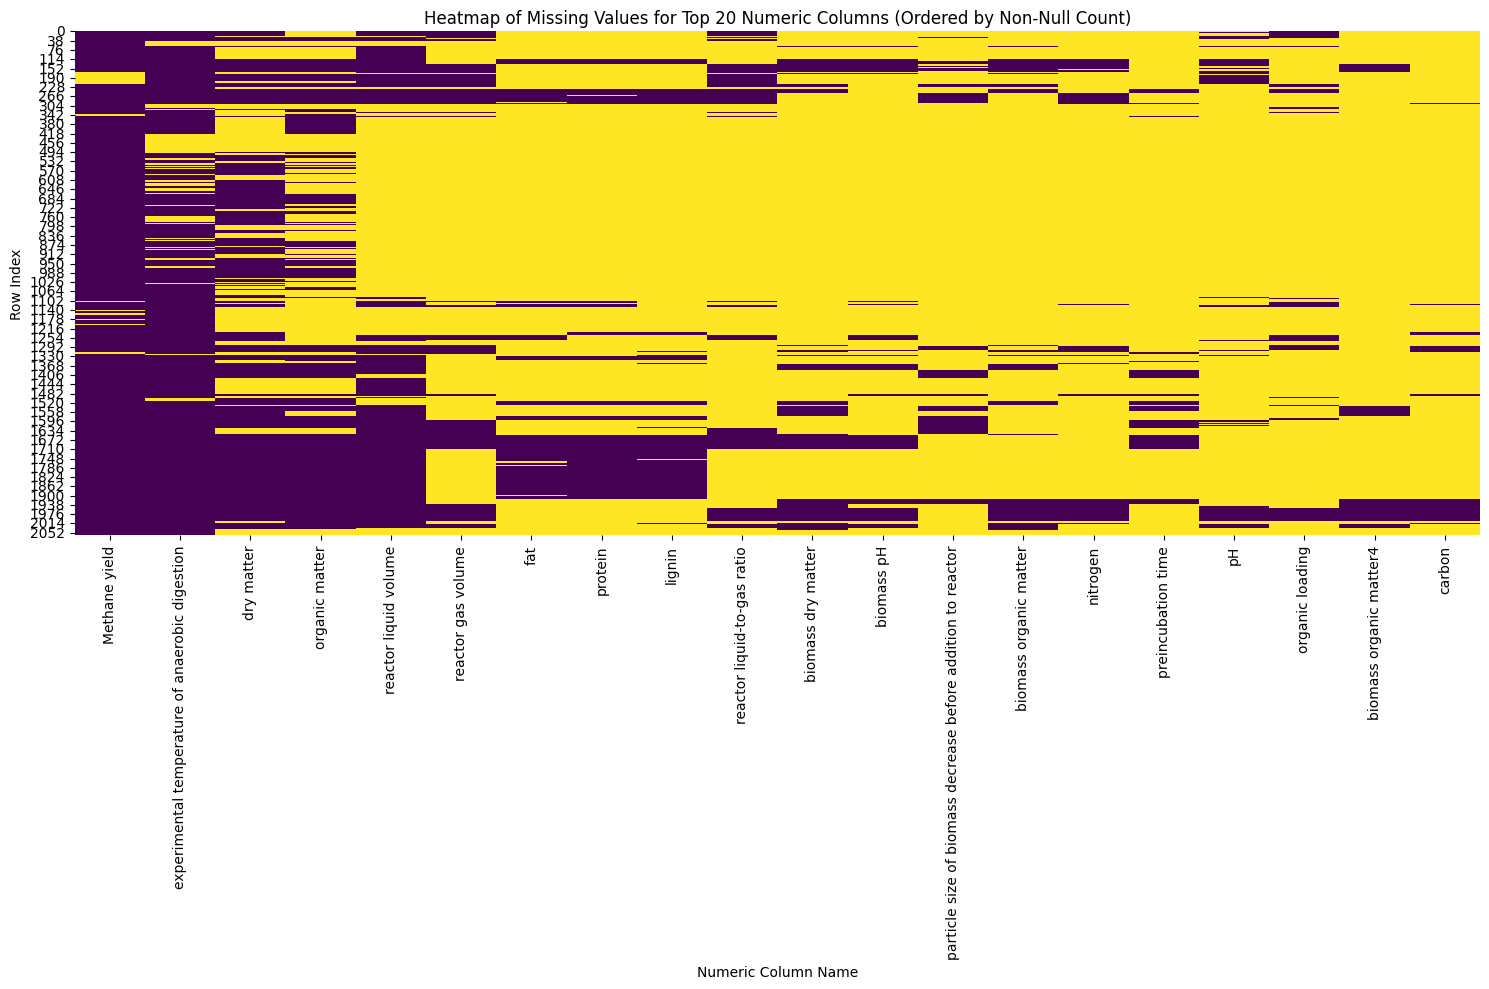

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Get the names of the top 20 numeric columns by non-null values
top_20_numeric_cols = top_20_non_null_numeric.index.tolist()

# Filter the DataFrame to include only these top 20 columns
df_top_20_numeric = df[top_20_numeric_cols]

# Recalculate null values for these columns to ensure proper ordering in the heatmap
# (though the filtering itself should maintain the order based on top_20_numeric_cols)
null_values_top_20 = df_top_20_numeric.isnull()

# Plotting the heatmap for these top 20 numeric columns
plt.figure(figsize=(15, 10))
sns.heatmap(null_values_top_20, cbar=False, cmap='viridis')
plt.title('Heatmap of Missing Values for Top 20 Numeric Columns (Ordered by Non-Null Count)')
plt.ylabel('Row Index')
plt.xlabel('Numeric Column Name')
plt.tight_layout()
plt.show()



## Interpretación

Este código genera un **mapa de calor (*heatmap*) para visualizar la distribución de los valores faltantes en las 20 columnas numéricas con mayor cantidad de datos disponibles** del DataFrame original (`df`).

A diferencia del mapa de calor anterior, que representa todas las variables del conjunto de datos, este procedimiento se concentra exclusivamente en las 20 columnas numéricas previamente identificadas como las de mayor cantidad de valores no nulos.

El objetivo es **evaluar la completitud de las variables numéricas con mayor disponibilidad de información**, facilitando la identificación de patrones de ausencia de datos y proporcionando elementos para seleccionar las variables que podrían utilizarse en análisis estadísticos o modelos predictivos.

### Procedimiento

1. **Recupera los nombres de las 20 columnas numéricas seleccionadas previamente** mediante `top_20_non_null_numeric.index.tolist()`. Esta instrucción convierte el índice de la serie `top_20_non_null_numeric` en una lista de nombres de columnas, conservando el orden descendente de disponibilidad de datos.

2. **Construye un nuevo DataFrame** denominado `df_top_20_numeric`, utilizando `df[top_20_numeric_cols]`. Este DataFrame contiene únicamente las 20 columnas numéricas seleccionadas, pero conserva todos los registros del conjunto de datos original.

3. **Identifica los valores faltantes** mediante `df_top_20_numeric.isnull()`. Esta función genera una matriz booleana con las mismas dimensiones del DataFrame filtrado:
   - **`True`:** indica que el elemento contiene un valor nulo (`NaN`).
   - **`False`:** indica que el elemento contiene un valor no nulo.

4. **Almacena la matriz de valores faltantes** en la variable `null_values_top_20`. Esta matriz constituye la información que se utilizará para generar el mapa de calor.

5. **Define las dimensiones de la figura** mediante `plt.figure(figsize=(15, 10))`. Se establece un área gráfica de 15 pulgadas de ancho por 10 pulgadas de alto, adecuada para representar las 20 variables seleccionadas.

6. **Genera el mapa de calor** mediante `sns.heatmap(null_values_top_20, cbar=False, cmap='viridis')`. Cada celda representa la disponibilidad de información de una variable para un registro determinado.

7. **Aplica la paleta de colores `viridis`**, utilizando dos tonalidades para distinguir los valores booleanos:
   - **Morado oscuro:** corresponde a valores no nulos (`False`, equivalente a 0).
   - **Amarillo:** corresponde a valores nulos (`True`, equivalente a 1).

8. **Desactiva la barra de colores** mediante `cbar=False`, simplificando la representación gráfica.

9. **Asigna un título descriptivo** mediante `plt.title()`, indicando que la gráfica representa los valores faltantes de las 20 columnas numéricas, ordenadas según su cantidad de valores no nulos.

10. **Identifica los ejes de la gráfica**:
    - **Eje horizontal (X):** nombres de las columnas numéricas seleccionadas.
    - **Eje vertical (Y):** índices de los registros del DataFrame.

11. **Ajusta la distribución de los elementos gráficos** mediante `plt.tight_layout()`, evitando que los nombres de las variables o las etiquetas se superpongan o queden fuera de la figura.

12. **Muestra el mapa de calor** mediante `plt.show()`, permitiendo examinar visualmente la distribución de los valores faltantes.

### Interpretación de la gráfica

El mapa de calor presenta las 20 variables numéricas seleccionadas, organizadas de izquierda a derecha según la cantidad de valores no nulos, de mayor a menor.

Esta organización permite comparar visualmente la disponibilidad de información entre las variables.

La distribución de colores puede interpretarse de la siguiente manera:

1. **Columnas completamente moradas:** variables que contienen información válida en todos los registros.
2. **Columnas predominantemente moradas:** variables con una elevada proporción de datos disponibles.
3. **Columnas con regiones amarillas:** variables que presentan valores faltantes en determinados registros.
4. **Franjas horizontales amarillas:** registros que carecen de información en varias de las variables seleccionadas.
5. **Bloques amarillos coincidentes entre columnas:** grupos de variables que presentan ausencia de información en los mismos registros.

Debido a que las columnas están ordenadas según su cantidad de valores no nulos, se espera que las variables situadas hacia la izquierda presenten una menor proporción de celdas amarillas que las situadas hacia la derecha.

Sin embargo, esta organización no implica que los valores faltantes se encuentren agrupados en posiciones específicas dentro de cada columna.

### Observaciones importantes

- El análisis utiliza las 20 columnas numéricas identificadas previamente en `top_20_non_null_numeric`, por lo que esta variable debe existir antes de ejecutar el código.
- La selección de columnas se realiza a partir del DataFrame original (`df`), sin eliminar registros.
- El orden de las columnas corresponde a la cantidad de valores no nulos, pero **las filas conservan su orden original**.
- La instrucción `df_top_20_numeric.isnull()` identifica los valores faltantes, pero no modifica el orden de las columnas. Este orden ya quedó establecido al construir `df_top_20_numeric`.
- El mapa de calor permite identificar patrones de ausencia de información, pero no proporciona directamente el número exacto ni el porcentaje de valores faltantes por variable.
- Aunque las 20 columnas seleccionadas presentan la mayor disponibilidad de datos, esto no garantiza que sean las más relevantes para explicar o predecir una variable de interés.
- La coincidencia de valores faltantes entre diferentes columnas puede indicar que determinadas mediciones no se realizaron conjuntamente o que existen diferencias entre los procedimientos de recopilación de datos.
- La identificación visual de estos patrones no permite determinar por sí sola las causas de la ausencia de información.

### Relación con el análisis anterior

Este procedimiento complementa la gráfica de barras de las 20 columnas numéricas con mayor cantidad de valores no nulos.

Mientras que la gráfica de barras permite conocer **cuántos registros válidos contiene cada variable**, el mapa de calor permite identificar **en qué registros se encuentran los valores faltantes**.

Por tanto, ambas representaciones proporcionan información complementaria:

- **Gráfica de barras:** cuantifica la disponibilidad de información por variable.
- **Mapa de calor:** muestra la distribución de los valores faltantes entre variables y registros.

Esta combinación permite evaluar no solamente la cantidad de datos disponibles, sino también la posibilidad de utilizar conjuntamente diferentes variables en un análisis posterior.

### Conclusión

Esta etapa permite realizar una **evaluación visual detallada de la completitud de las 20 variables numéricas con mayor disponibilidad de información** del conjunto de datos.

La representación facilita la identificación de variables con pocos valores faltantes, registros incompletos y posibles patrones de ausencia simultánea de información.

Los resultados pueden utilizarse como apoyo para seleccionar variables, establecer criterios de filtrado de registros o evaluar la necesidad de aplicar métodos de imputación antes de construir modelos estadísticos o predictivos.

Sin embargo, la selección definitiva de variables debe considerar también su significado físico, su relevancia para el problema estudiado, la calidad de las mediciones y su relación con la variable objetivo.

**El procedimiento es exclusivamente exploratorio y visual:** no elimina registros, no modifica los valores originales, no realiza imputaciones y no altera el conjunto de datos inicial.


Original DataFrame shape: (2062, 71)
Filtered DataFrame shape (non-null 'lignin'): (417, 71)


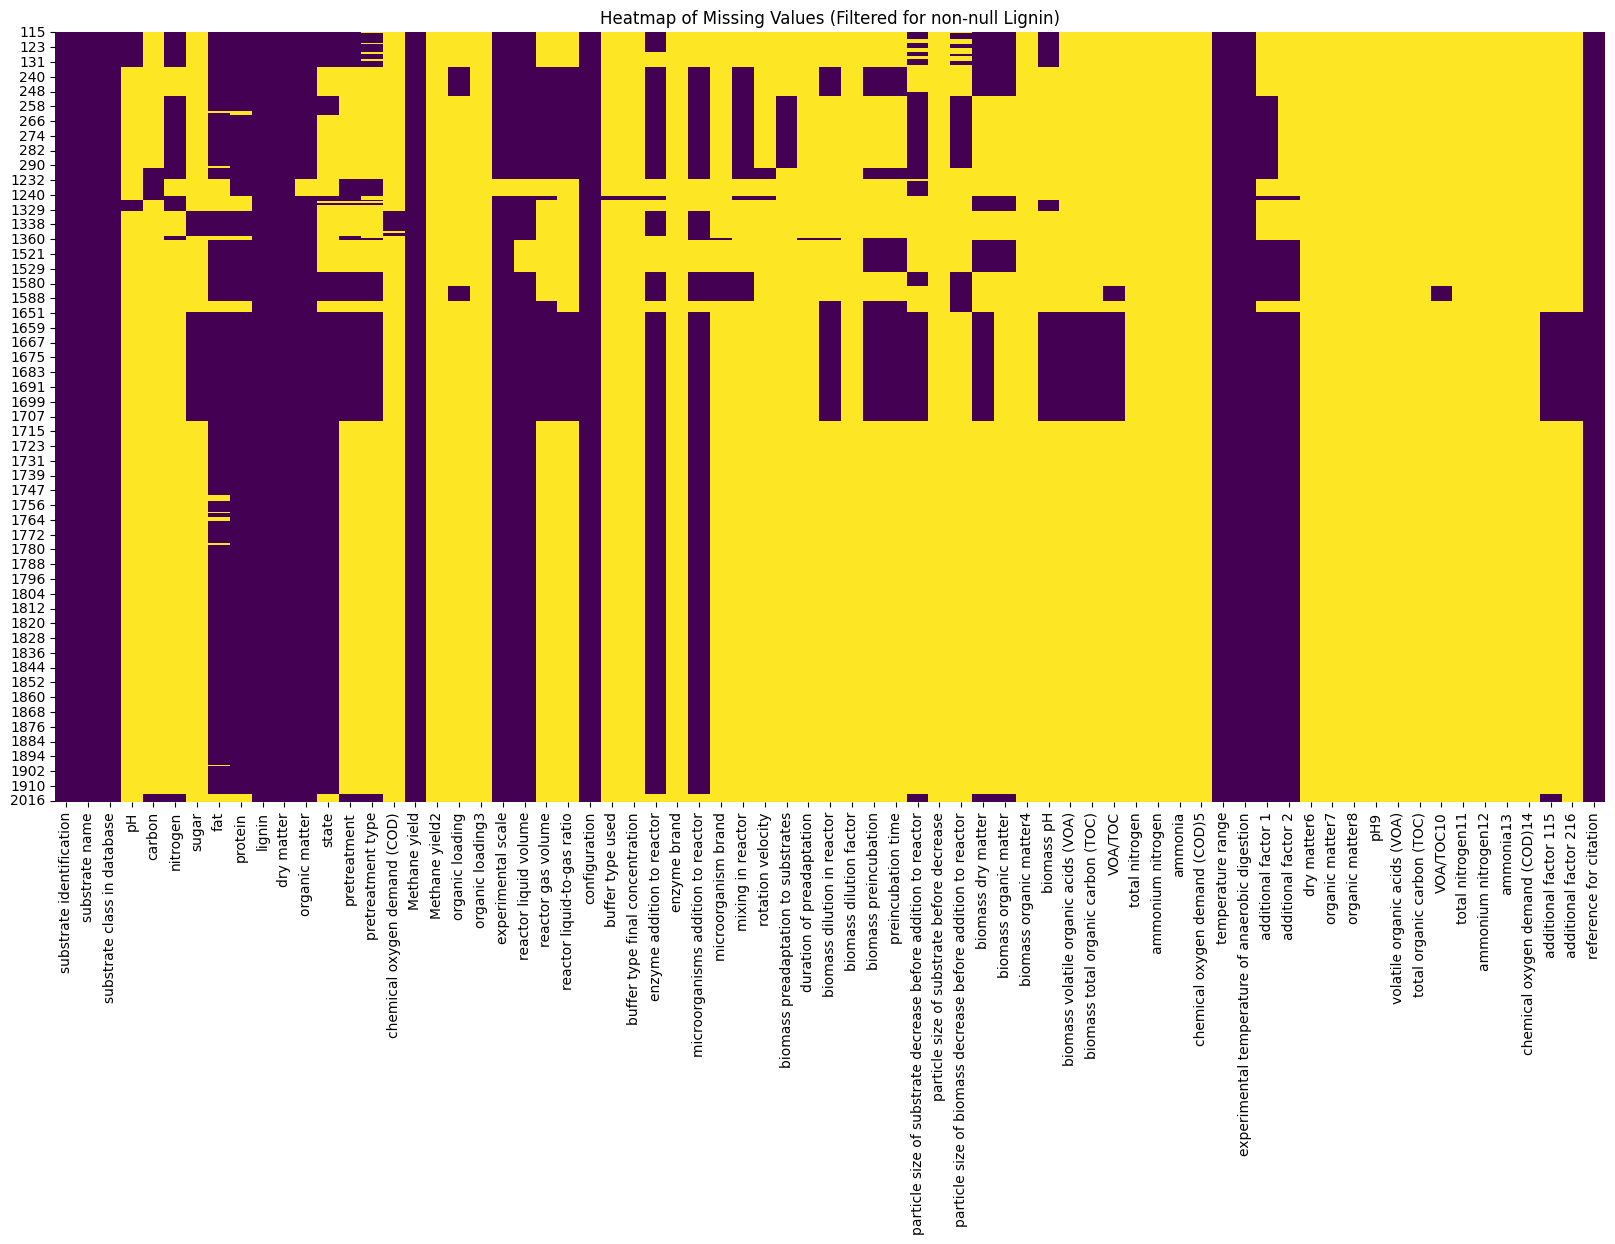

In [8]:

# Filter the DataFrame to include only rows where 'lignin' is not null
df_filtered_lignin = df[df['lignin'].notna()]

print(f"Original DataFrame shape: {df.shape}")
print(f"Filtered DataFrame shape (non-null 'lignin'): {df_filtered_lignin.shape}")

# Plotting the heatmap for the filtered DataFrame
plt.figure(figsize=(20, 10))
sns.heatmap(df_filtered_lignin.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap of Missing Values (Filtered for non-null Lignin)')
plt.show()



## Interpretación

Este código realiza una **selección de registros del conjunto de datos original (`df`), utilizando la disponibilidad de información de la variable `lignin` como criterio de filtrado**.

A diferencia de los procedimientos anteriores, que se concentraban en evaluar la presencia de valores faltantes, esta etapa modifica el conjunto de datos de trabajo al conservar únicamente los registros que contienen un valor válido de `lignin`.

Posteriormente, genera un nuevo mapa de calor para examinar la distribución de los valores faltantes en las demás variables de los registros seleccionados.

### Procedimiento

1. **Filtra los registros con información disponible de `lignin`** mediante la instrucción:

   ```python
   df_filtered_lignin = df[df['lignin'].notna()]
   ```

   La función `notna()` identifica los registros en los que `lignin` contiene un valor no nulo. El resultado se almacena en un nuevo DataFrame denominado `df_filtered_lignin`.

2. **Compara las dimensiones del conjunto de datos original y del filtrado** mediante `df.shape` y `df_filtered_lignin.shape`.

   Los resultados obtenidos son:

   - **DataFrame original:** 2,062 registros y 71 columnas.
   - **DataFrame filtrado:** 417 registros y 71 columnas.

   Por tanto, se conservan **417 registros (20.22 % del total)** y se excluyen 1,645 registros (79.78 %) que no contienen información válida de `lignin`.

3. **Genera un nuevo mapa de calor** utilizando `df_filtered_lignin.isnull()`, que permite visualizar la distribución de los valores faltantes en las 71 columnas de los 417 registros seleccionados.

### Interpretación de los resultados

El filtrado produce una reducción considerable en el número de registros disponibles, pasando de 2,062 a 417 observaciones.

Esta reducción tiene las siguientes implicaciones:

- **La variable `lignin` queda completamente disponible** en el conjunto filtrado, ya que todos los registros conservados contienen un valor no nulo.
- **Las demás variables pueden continuar presentando valores faltantes**, debido a que el criterio de selección se aplica exclusivamente a `lignin`.
- **Se conserva la estructura original de 71 columnas**, aunque algunas podrían quedar completamente vacías después del filtrado.
- **El nuevo mapa de calor permite identificar la disponibilidad conjunta de información** en los registros que contienen mediciones de `lignin`.

### Observaciones importantes

- El filtrado se realiza sobre el DataFrame original (`df`) y no sobre el conjunto de las 20 columnas numéricas analizadas anteriormente.
- La operación no elimina columnas, únicamente registros.
- El DataFrame original permanece sin modificaciones.
- La reducción de registros puede afectar la representatividad estadística del conjunto de datos si la ausencia de información de `lignin` está relacionada con determinadas características de las observaciones.
- La selección garantiza la disponibilidad de `lignin`, pero no asegura que las demás variables tengan información suficiente para realizar análisis conjuntos.
- El procedimiento resulta especialmente útil cuando `lignin` constituye una variable de interés o una variable objetivo para el desarrollo de modelos predictivos.

### Conclusión

Esta etapa establece un **subconjunto de 417 registros con información válida de `lignin`**, que representa aproximadamente el 20.22 % del conjunto de datos original.

El mapa de calor permite evaluar la disponibilidad de las demás variables dentro de este subconjunto, proporcionando información para las siguientes etapas de depuración y selección de columnas.

**El procedimiento introduce el primer filtrado de registros basado en una variable específica**, conservando todas las columnas y sin modificar ni imputar los valores faltantes de las demás variables.


In [9]:

# Drop columns that are entirely null in the df_filtered_lignin DataFrame
df_lignin_non_empty_cols = df_filtered_lignin.dropna(axis=1, how='all')

print(f"Shape of DataFrame filtered for non-null 'lignin' and non-empty columns: {df_lignin_non_empty_cols.shape}")
print(df_lignin_non_empty_cols.info())


Shape of DataFrame filtered for non-null 'lignin' and non-empty columns: (417, 51)
<class 'pandas.core.frame.DataFrame'>
Index: 417 entries, 115 to 2016
Data columns (total 51 columns):
 #   Column                                                          Non-Null Count  Dtype  
---  ------                                                          --------------  -----  
 0   substrate identification                                        417 non-null    object 
 1   substrate name                                                  417 non-null    object 
 2   substrate class in database                                     417 non-null    object 
 3   pH                                                              25 non-null     float64
 4   carbon                                                          21 non-null     float64
 5   nitrogen                                                        78 non-null     float64
 6   sugar                                                           7


## Interpretación

El código continúa con el DataFrame filtrado anteriormente (`df_filtered_lignin`), que contiene **417 registros y 71 columnas**.

La instrucción:

```python
.dropna(axis=1, how='all')
```

elimina únicamente las columnas cuyos valores son todos nulos (`NaN`).

Los parámetros y funciones utilizados son:

- **`axis=1`**: indica que se eliminarán columnas, no filas.
- **`how='all'`**: elimina una columna solamente cuando todos sus registros son nulos.
- **`shape`**: muestra las dimensiones del DataFrame resultante.
- **`info()`**: muestra los nombres de las columnas, la cantidad de valores no nulos y los tipos de datos.

### Observación importante

El número de filas permanecerá en **417**, mientras que el número de columnas podría disminuir.

Además, `info()` ya imprime su resultado, por lo que la instrucción:

```python
print(df_lignin_non_empty_cols.info())
```

mostrará un `None` adicional al final.

Es preferible utilizar directamente:

```python
df_lignin_non_empty_cols.info()
```

### Conclusión

Esta etapa permite eliminar variables que no contienen información útil en ninguno de los 417 registros seleccionados, conservando todas las columnas que tienen al menos un valor válido.

El procedimiento no modifica los valores existentes ni elimina registros, por lo que constituye una etapa de limpieza estructural del conjunto de datos.


In [10]:

# Calculate the number of non-null values in the 'fat' column from the df_lignin_non_empty_cols DataFrame
fat_non_null_count = df_lignin_non_empty_cols['fat'].count()

# Get non-null counts for all columns in the df_lignin_non_empty_cols DataFrame
non_null_counts_filtered = df_lignin_non_empty_cols.count()

# Identify columns to keep (non-null count >= fat_non_null_count)
columns_to_keep = non_null_counts_filtered[non_null_counts_filtered >= fat_non_null_count].index.tolist()

# Create a new DataFrame with only the selected columns
df_fat_column_cleaned = df_lignin_non_empty_cols[columns_to_keep]

print(f"Shape of DataFrame after removing columns with less non-null values than 'fat': {df_fat_column_cleaned.shape}")
print(df_fat_column_cleaned.info())


Shape of DataFrame after removing columns with less non-null values than 'fat': (417, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 417 entries, 115 to 2016
Data columns (total 15 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   substrate identification                         417 non-null    object 
 1   substrate name                                   417 non-null    object 
 2   substrate class in database                      417 non-null    object 
 3   fat                                              378 non-null    float64
 4   protein                                          395 non-null    float64
 5   lignin                                           417 non-null    float64
 6   dry matter                                       417 non-null    float64
 7   organic matter                                   408 non-null    float64
 8   Methane yield         


## Interpretación

Este código realiza una nueva etapa de depuración del conjunto de datos, utilizando la columna `fat` como referencia para determinar qué variables conservar.

El procedimiento realiza lo siguiente:

1. **Cuenta los valores no nulos de `fat`**, estableciendo el umbral mínimo de información disponible.
2. **Cuenta los valores no nulos de todas las columnas** del DataFrame.
3. **Selecciona las columnas** que tienen una cantidad de valores no nulos mayor o igual a la de `fat`.
4. **Construye un nuevo DataFrame** llamado `df_fat_column_cleaned`, que contiene únicamente las columnas seleccionadas.
5. **Muestra las dimensiones y características** del conjunto de datos resultante.

### Observación importante

Este procedimiento elimina columnas con información insuficiente respecto al umbral definido, pero no elimina filas ni completa los valores faltantes.

Por tanto, el DataFrame conservará los **417 registros** obtenidos en las etapas anteriores, aunque tendrá un número menor o igual de columnas.

La columna `fat` siempre se conservará porque cumple exactamente con el umbral establecido.


Por tanto, el DataFrame conservará los 417 registros obtenidos en las etapas anteriores, aunque tendrá un número menor o igual de columnas.

La columna fat siempre se conservará porque cumple exactamente con el umbral establecido.

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Re-define df_filtered_lignin (from previous steps, to ensure availability)
df_filtered_lignin = df[df['lignin'].notna()]

# Re-define df_lignin_non_empty_cols (from previous steps, to ensure availability)
df_lignin_non_empty_cols = df_filtered_lignin.dropna(axis=1, how='all')

# Calculate the number of non-null values in the 'fat' column from df_lignin_non_empty_cols
fat_non_null_count = df_lignin_non_empty_cols['fat'].count()

# Get non-null counts for all columns in df_lignin_non_empty_cols
non_null_counts_lignin = df_lignin_non_empty_cols.count()

# Identify columns to keep: non-null count >= fat_non_null_count
columns_to_keep_refined = [
    col for col, count in non_null_counts_lignin.items()
    if count >= fat_non_null_count
]

# Explicitly add 'nitrogen' to the list of columns to keep if it's not already there
if 'nitrogen' not in columns_to_keep_refined:
    columns_to_keep_refined.append('nitrogen')

# Ensure 'nitrogen' is ordered correctly if you want it in a specific position, e.g., after 'carbon' or at the beginning



## Interpretación

Este código continúa la depuración de datos de las etapas anteriores, pero introduce una modificación importante: **conservar obligatoriamente la variable `nitrogen`**, aunque tenga menos valores disponibles que `fat`.

El procedimiento realiza lo siguiente:

1. Filtra los registros que tienen un valor válido de `lignin`.
2. Elimina las columnas completamente vacías.
3. Determina el número de valores disponibles en `fat`.
4. Conserva las columnas cuyo número de valores no nulos sea mayor o igual al de `fat`.
5. Incorpora `nitrogen` a la selección, independientemente de la cantidad de valores faltantes que contenga.

### Observación técnica

La instrucción que agrega `nitrogen` supone que esa columna existe en el DataFrame original y que no fue eliminada por estar completamente vacía. Si no existe, se producirá un error cuando posteriormente se intente seleccionar.

Además, la última línea del código es únicamente un comentario: todavía no se implementa el reordenamiento de la columna `nitrogen`.

### Conclusión

Esta etapa permite conservar una variable considerada importante para el análisis, incluso cuando no satisface el criterio general de disponibilidad de datos.
